## Why a Synthetic (Fake) Signal First? The Ground-Truth Idea


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def make_trace(hr_bpm=72, seconds=30, fs=30, noise=0.4, seed=1):
    """Fake RGB face signal: baseline colour + pulse wave + noise."""
    t = np.arange(0, seconds, 1 / fs)                                # time points: 0..30 s
    pulse = 0.5 + 0.5 * np.sin(2 * np.pi * (hr_bpm / 60) * t)        # wave, 0..1, at hr_bpm speed
    base = np.array([110.0, 95.0, 80.0])                             # average skin colour (R, G, B)
    amp = np.array([2.0, 6.0, 2.5])                                  # pulse strength per colour
    return base + pulse[:, None] * amp + np.random.default_rng(seed).normal(0, noise, (len(t), 3))

trace = make_trace(72)
print("trace shape:", trace.shape)


trace shape: (900, 3)


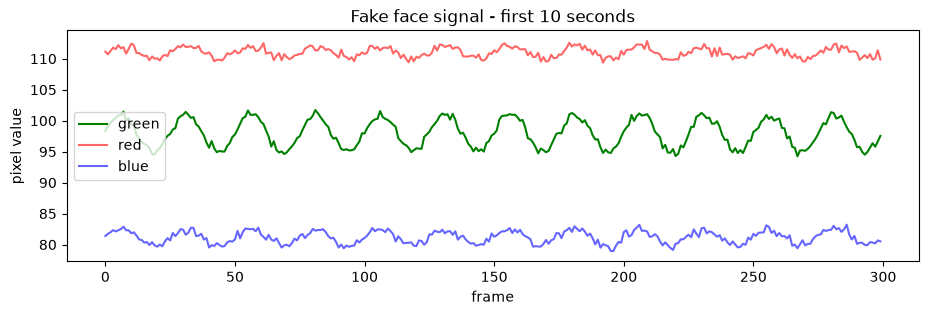

In [2]:
plt.figure(figsize=(11, 3))
plt.plot(trace[:300, 1], color="green", label="green")
plt.plot(trace[:300, 0], color="red", alpha=.6, label="red")
plt.plot(trace[:300, 2], color="blue", alpha=.6, label="blue")
plt.legend()
plt.title("Fake face signal - first 10 seconds")
plt.xlabel("frame")
plt.ylabel("pixel value")
plt.show()


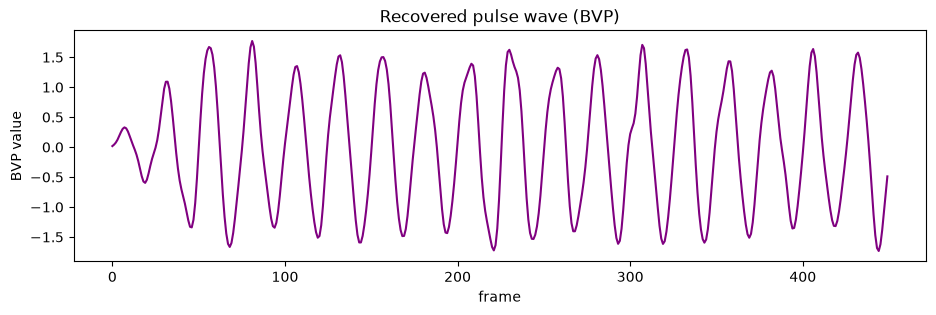

BVP ready: 900 samples


In [7]:
from scipy.signal import butter, filtfilt


def detrend(s):
    x = np.arange(len(s))
    return s - np.polyval(np.polyfit(x, s, 1), x)


def bandpass(s, fs, low=0.7, high=4.0):
    b, a = butter(4, [low / (fs / 2), high / (fs / 2)], btype="band")
    return filtfilt(b, a, s) if len(s) > 45 else s - s.mean()


def pos_rppg(rgb, fs):
    rgb = np.asarray(rgb, dtype=float)
    win = int(1.6 * fs)
    bvp = np.zeros(len(rgb))

    for n in range(win, len(rgb) + 1):
        w = rgb[n - win:n]
        cn = w / w.mean(axis=0)
        xs = cn[:, 1] - cn[:, 2]
        ys = cn[:, 1] + cn[:, 2] - 2 * cn[:, 0]
        alpha = np.std(xs) / (np.std(ys) or 1e-6)
        pulse = xs + alpha * ys
        bvp[n - win:n] += pulse - pulse.mean()

    return bvp


# run it
bvp_raw = pos_rppg(trace, 30)
bvp = bandpass(detrend(bvp_raw), 30)

plt.figure(figsize=(11, 3))
plt.plot(bvp[:450], color="purple")
plt.title("Recovered pulse wave (BVP)")
plt.xlabel("frame")
plt.ylabel("BVP value")
plt.show()
print("BVP ready:", len(bvp), "samples")


Injected truth : 72 bpm
FFT measured   : 72.0 bpm   confidence: 0.92


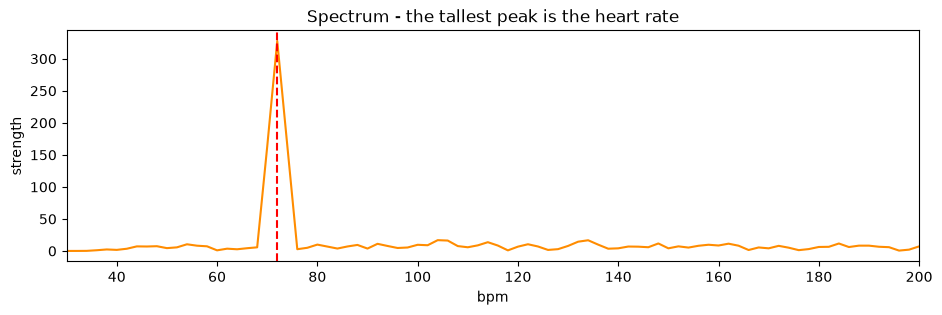

In [8]:
def estimate_hr(bvp, fs):
    f = bandpass(detrend(bvp), fs)
    spec = np.abs(np.fft.rfft(f * np.hanning(len(f))))
    bpm_axis = np.fft.rfftfreq(len(f), d=1 / fs) * 60
    band = (bpm_axis >= 42) & (bpm_axis <= 180)
    s = np.where(band, spec, 0)
    peak = int(np.argmax(s))
    snr = spec[peak] / (np.median(spec[band]) or 1e-9)
    confidence = float(np.clip(snr / (snr + 4), 0, 0.99))
    return float(bpm_axis[peak]), confidence, bpm_axis, spec


hr, conf, bpm_axis, spec = estimate_hr(bvp_raw, 30)

print("Injected truth :", 72, "bpm")
print("FFT measured   :", hr, "bpm   confidence:", round(conf, 2))

plt.figure(figsize=(11, 3))
plt.plot(bpm_axis, spec, color="darkorange")
plt.xlim(30, 200)
plt.axvline(hr, color="red", linestyle="--")
plt.title("Spectrum - the tallest peak is the heart rate")
plt.xlabel("bpm"); plt.ylabel("strength")
plt.show()

## HRV (Heart Rate Variability) and Signal Quality (SQI): One Function That Reads the Whole Wave


heart_rate_bpm     72.0
hrv_sdnn_ms        47.8
hrv_rmssd_ms       91.4
hrv_pnn50_pct      45.5
confidence         0.921
signal_quality     0.858
num_beats          35
_upstroke          -4e-05
_perfusion_index   0.02193
verdict: good


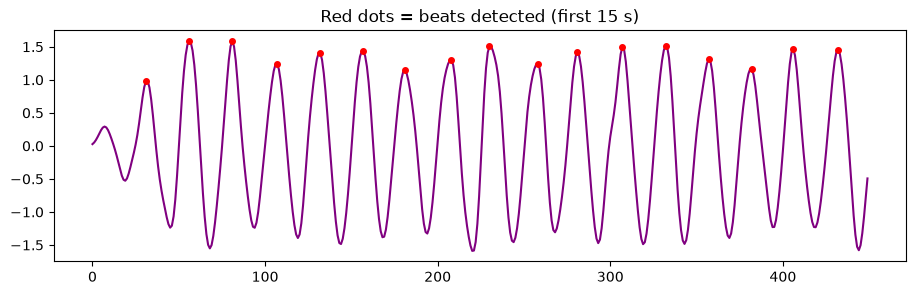

In [14]:
from scipy.signal import find_peaks


def extract_features(rgb, fs):
    rgb = np.asarray(rgb, dtype=float)
    raw = pos_rppg(rgb, fs)
    b = bandpass(detrend(raw), fs)
    hr, confidence, _, _ = estimate_hr(raw, fs)

    # find individual beats, protected from double-counting
    b = np.convolve(b, np.ones(5) / 5, mode="same")
    min_dist = int(fs * 60 / (hr * 1.3))
    peaks, _ = find_peaks(b, distance=max(min_dist, 1), prominence=np.std(b) * 0.5)

    # RR intervals (ms) -> HRV
    rr = np.diff(peaks) / fs * 1000
    rr = rr[(rr >= 333) & (rr <= 1500)]
    if len(rr) >= 4:
        sdnn = float(np.std(rr))
        rmssd = float(np.sqrt(np.mean(np.diff(rr) ** 2)))
        pnn50 = float(np.mean(np.abs(np.diff(rr)) > 50) * 100)
        hr_rr = 60000 / float(np.mean(rr))
        if abs(hr_rr - hr) <= 8:
            hr = 0.7 * hr + 0.3 * hr_rr          # blend only when they agree
    else:
        sdnn, rmssd, pnn50 = 35.0, 28.0, 8.0     # neutral priors

    # two morphology features for the ML models
    norm = (b - b.min()) / ((b.max() - b.min()) or 1e-9)
    upstroke = float(np.mean(np.gradient(norm)))
    perfusion = float(np.std(rgb[:, 1]) / (np.mean(rgb[:, 1]) or 1e-9))

    # signal quality: 70% spectral confidence + 30% stillness
    green = rgb[:, 1]
    motion = float(np.mean(np.abs(np.diff(green))) / (np.std(green) or 1e-9))
    quality = float(np.clip(confidence * 0.7 + (1 - min(motion, 1.0)) * 0.3, 0, 1))

    return {"heart_rate_bpm": round(hr, 1), "hrv_sdnn_ms": round(sdnn, 1),
            "hrv_rmssd_ms": round(rmssd, 1), "hrv_pnn50_pct": round(pnn50, 1),
            "confidence": round(confidence, 3), "signal_quality": round(quality, 3),
            "num_beats": int(len(peaks)), "_upstroke": round(upstroke, 5),
            "_perfusion_index": round(perfusion, 5), "_bvp": b, "_peaks": peaks}


def quality_verdict(q):
    if q >= 0.75: return "good"
    if q >= 0.5: return "acceptable - stay still and face the light"
    return "poor - improve lighting, stay still and re-scan"


feat = extract_features(trace, 30)
for k, v in feat.items():
    if not k.startswith("_bvp") and k != "_peaks":
        print(f"{k:18s} {v}")
print("verdict:", quality_verdict(feat["signal_quality"]))

# see the beats it found
p = feat["_peaks"]; b = feat["_bvp"]
plt.figure(figsize=(11, 3))
plt.plot(b[:450], color="purple")
plt.plot(p[p < 450], b[p[p < 450]], "ro", markersize=4)
plt.title("Red dots = beats detected (first 15 s)")
plt.show()


## Load the Dataset 

In [ ]:
import pandas as pd

df = pd.read_csv("dataset_full.csv")



In [20]:
print(df.columns.tolist())          # always LOOK at the real names first

FEATURES = ["heart_rate_bpm", "hrv_sdnn_ms", "hrv_rmssd_ms", "upstroke_feature",
            "perfusion_index", "age_years", "bmi", "sex_M1_F0",
            "smoker", "family_history", "activity_level"]

X = df[FEATURES].to_numpy()
y_bp = df[["systolic_bp_mmhg", "diastolic_bp_mmhg"]].to_numpy()
y_met = df[["cholesterol_mg_dl", "glucose_mg_dl"]].to_numpy()

print("dataset:", df.shape)
print("features X:", X.shape, "| BP targets:", y_bp.shape, "| metabolic targets:", y_met.shape)
df.head()


['heart_rate_bpm', 'hrv_sdnn_ms', 'hrv_rmssd_ms', 'upstroke_feature', 'perfusion_index', 'age_years', 'bmi', 'sex_M1_F0', 'smoker', 'family_history', 'activity_level', 'systolic_bp_mmhg', 'diastolic_bp_mmhg', 'cholesterol_mg_dl', 'glucose_mg_dl']
dataset: (4000, 15)
features X: (4000, 11) | BP targets: (4000, 2) | metabolic targets: (4000, 2)


,heart_rate_bpm,hrv_sdnn_ms,hrv_rmssd_ms,upstroke_feature,perfusion_index,age_years,bmi,sex_M1_F0,smoker,family_history,activity_level,systolic_bp_mmhg,diastolic_bp_mmhg,cholesterol_mg_dl,glucose_mg_dl
0,59.967,36.802,23.052,-0.157,4.274,62.115,20.317,0.0,1.0,0.0,0.0,120.629,75.925,224.294,86.653
1,64.122,42.911,34.912,1.064,6.026,43.016,18.265,1.0,1.0,1.0,1.0,112.176,69.700,199.792,74.133
2,74.312,40.119,32.636,0.227,4.632,66.940,31.087,0.0,1.0,1.0,2.0,144.624,79.559,233.328,128.834
3,78.798,35.404,24.967,-0.442,4.494,57.750,35.901,1.0,0.0,1.0,1.0,148.998,84.735,262.960,133.425
4,67.120,58.431,54.495,0.109,4.925,23.368,22.859,0.0,1.0,0.0,1.0,104.196,64.998,181.847,96.622


## Training the Model

In [22]:
import pickle, os
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

# Split: 3,200 patients for training, 800 sealed away for honest testing
X_train, X_test, bp_train, bp_test, met_train, met_test = train_test_split(
    X, y_bp, y_met, test_size=0.2, random_state=1)
print("Training patients:", X_train.shape[0], "| Test patients:", X_test.shape[0])

# Model 1 - Blood Pressure (BP): predicts Systolic (SBP) and Diastolic (DBP) together
bp_model = RandomForestRegressor(n_estimators=50, max_depth=7,
                                 min_samples_leaf=4, n_jobs=-1,
                                 random_state=1).fit(X_train, bp_train)

# Model 2 - Metabolic: predicts Cholesterol and Glucose together
met_model = RandomForestRegressor(n_estimators=50, max_depth=7,
                                  min_samples_leaf=4, n_jobs=-1,
                                  random_state=1).fit(X_train, met_train)

# Judge both models ONLY on the 800 unseen patients - Mean Absolute Error (MAE)
print("Blood Pressure (BP)  -> Systolic (SBP) MAE:",
      round(mean_absolute_error(bp_test[:, 0], bp_model.predict(X_test)[:, 0]), 2),
      "| Diastolic (DBP) MAE:",
      round(mean_absolute_error(bp_test[:, 1], bp_model.predict(X_test)[:, 1]), 2), "mmHg")
print("Metabolic            -> Cholesterol MAE:",
      round(mean_absolute_error(met_test[:, 0], met_model.predict(X_test)[:, 0]), 2),
      "| Glucose MAE:",
      round(mean_absolute_error(met_test[:, 1], met_model.predict(X_test)[:, 1]), 2), "mg/dL")

# Freeze both trained models into one file for the application to load later
with open("models/vitals_models.pkl", "wb") as f:
    pickle.dump({"bp": bp_model, "metabolic": met_model}, f)
print("Saved models/vitals_models.pkl:",
      round(os.path.getsize("models/vitals_models.pkl") / 1e6, 2), "MB")


Training patients: 3200 | Test patients: 800
Blood Pressure (BP)  -> Systolic (SBP) MAE: 4.77 | Diastolic (DBP) MAE: 3.74 mmHg
Metabolic            -> Cholesterol MAE: 12.03 | Glucose MAE: 6.13 mg/dL
Saved models/vitals_models.pkl: 1.86 MB


In [23]:
# Load the frozen models
MODELS = None
try:
    with open("models/vitals_models.pkl", "rb") as f:
        MODELS = pickle.load(f)
    print("Models loaded: OK")
except Exception:
    print("Models loaded: FAILED - formula fallback will be used")


def build_features(feat, profile):
    """One row of 11 numbers, in the EXACT order the models were trained on."""
    sex = 1.0 if str(profile.get("sex", "M")).upper().startswith("M") else 0.0
    return np.array([[
        feat["heart_rate_bpm"],          # Heart Rate (HR)
        feat["hrv_sdnn_ms"],             # Heart Rate Variability - SDNN
        feat["hrv_rmssd_ms"],            # Heart Rate Variability - RMSSD
        feat["_upstroke"] * 1000,        # wave rise speed (scaled to training range)
        feat["_perfusion_index"] * 100,  # pulse strength (scaled to training range)
        float(profile.get("age", 35)),
        float(profile.get("bmi", 24)),   # Body Mass Index (BMI)
        sex,
        float(profile.get("smoker", 0)),
        float(profile.get("family_history", 0)),
        float(profile.get("activity_level", 2)),
    ]])


def estimate_bp(feat, profile):
    x = build_features(feat, profile)
    if MODELS and "bp" in MODELS:
        sbp, dbp = MODELS["bp"].predict(x)[0]          # the model's answer
    else:                                              # fallback formulas
        age, bmi, hr = x[0, 5], x[0, 6], x[0, 0]
        sbp = 92 + 0.55 * age + 0.9 * (bmi - 22) + 0.18 * (hr - 70)
        dbp = 60 + 0.32 * age + 0.6 * (bmi - 22) + 0.10 * (hr - 70)
    sbp = float(np.clip(sbp, 85, 200))                 # clamp to human range
    dbp = float(np.clip(dbp, 50, 130))
    if sbp < 120 and dbp < 80: category = "normal"
    elif sbp < 130 and dbp < 80: category = "elevated"
    elif sbp < 140 or dbp < 90: category = "high - stage 1"
    else: category = "high - stage 2"
    return {"systolic": round(sbp), "diastolic": round(dbp),
            "unit": "mmHg", "category": category,
            "type": "model estimate (screening)"}


def category_of(value, normal_below, high_from):
    if value < normal_below: return "normal"
    if value < high_from: return "borderline"
    return "high"


def estimate_metabolic(feat, profile):
    x = build_features(feat, profile)
    if MODELS and "metabolic" in MODELS:
        chol, glucose = MODELS["metabolic"].predict(x)[0]
    else:
        age, bmi = x[0, 5], x[0, 6]
        fam, act = x[0, 9], x[0, 10]
        chol = 155 + 0.85 * age + 3.2 * (bmi - 22) + 18 * fam - 5 * act
        glucose = 82 + 0.35 * age + 1.9 * (bmi - 22) + 10 * fam - 3 * act
    chol = float(np.clip(chol, 110, 340))
    glucose = float(np.clip(glucose, 65, 320))
    return {
        "cholesterol_total": {"value": round(chol), "unit": "mg/dL",
                              "category": category_of(chol, 200, 240),
                              "type": "screening estimate - confirm with lipid profile"},
        "blood_glucose_fasting_est": {"value": round(glucose), "unit": "mg/dL",
                                      "category": category_of(glucose, 100, 126),
                                      "type": "screening estimate - confirm with fasting lab test"},
    }


# Test it: the scan from Step 5 + one example person
profile = {"age": 40, "sex": "M", "bmi": 26, "smoker": 0,
           "family_history": 1, "activity_level": 1}
print("Blood Pressure (BP):", estimate_bp(feat, profile))
print("Metabolic:", estimate_metabolic(feat, profile))


Models loaded: OK
Blood Pressure (BP): {'systolic': 117, 'diastolic': 73, 'unit': 'mmHg', 'category': 'normal', 'type': 'model estimate (screening)'}
Metabolic: {'cholesterol_total': {'value': 216, 'unit': 'mg/dL', 'category': 'borderline', 'type': 'screening estimate - confirm with lipid profile'}, 'blood_glucose_fasting_est': {'value': 114, 'unit': 'mg/dL', 'category': 'borderline', 'type': 'screening estimate - confirm with fasting lab test'}}


## Testing Sample

In [24]:
# TEST 1 - Known truth in, correct answer out
test_feat = extract_features(make_trace(72), 30)
assert abs(test_feat["heart_rate_bpm"] - 72) <= 4, test_feat["heart_rate_bpm"]
assert test_feat["signal_quality"] > 0.4
print("Test 1 PASSED - Heart Rate (HR) recovered:", test_feat["heart_rate_bpm"], "beats per minute (bpm)")

# TEST 2 - Every output inside human physiological ranges
b = estimate_bp(test_feat, profile)
m = estimate_metabolic(test_feat, profile)
assert 85 <= b["systolic"] <= 200 and 50 <= b["diastolic"] <= 130
assert 110 <= m["cholesterol_total"]["value"] <= 340
assert 65 <= m["blood_glucose_fasting_est"]["value"] <= 320
print("Test 2 PASSED - Blood Pressure (BP), Cholesterol, Glucose all inside human ranges")

# TEST 3 - Frequency sweep (the test that catches what a single test misses)
for bpm in [55, 90, 120]:
    f = extract_features(make_trace(bpm), 30)
    assert abs(f["heart_rate_bpm"] - bpm) <= 3, (bpm, f["heart_rate_bpm"])
    print(f"  sweep {bpm} bpm -> measured {f['heart_rate_bpm']} bpm  OK")

print("\nALL TESTS PASSED")


Test 1 PASSED - Heart Rate (HR) recovered: 72.0 beats per minute (bpm)
Test 2 PASSED - Blood Pressure (BP), Cholesterol, Glucose all inside human ranges
  sweep 55 bpm -> measured 54.3 bpm  OK
  sweep 90 bpm -> measured 90.0 bpm  OK
  sweep 120 bpm -> measured 120.0 bpm  OK

ALL TESTS PASSED
